# TP: Estimación de movimiento y seguimiento de objetos

**Cátedra:** Visión por Computadora — 5to Año
**FICH-UNL (Santa Fe, Argentina)**

El objetivo es comprender los pasos del pipeline completo:

`Imagen → Preprocesamiento → Modelado de fondo / detección → Seguimiento → Análisis`

No se muestran *todas* las técnicas, sino un subconjunto representativo, y cada bloque termina en una **aplicación real**:

| Bloque | Técnicas usadas | Aplicación real |
|---|---|---|
| 1. Preprocesamiento | Filtros espaciales, ROI, submuestreo | Robustez frente a ruido de sensor |
| 2. Modelado de fondo | Diferencia de cuadros, promedio móvil, **MOG2**, **KNN**, **CNT** | Comparación de costo/calidad |
| 3. Objeto abandonado | Dos MOG2 con distinta tasa de aprendizaje | Alarma de seguridad (equipaje olvidado) |
| 4. Multi-objeto | MOG2 + **Kalman** + asignación húngara | Conteo bidireccional, mapa de calor, tiempo de permanencia, velocidad |
| 5. Flujo óptico | **Farnebäck**, **DIS**, **Lucas-Kanade + GFTT** | Estabilización de video y detección de contraflujo |
| 6. Seguimiento de un objeto | **KCF, MOSSE, CSRT, TLD** | Prueba de oclusión (corta y larga) y cámara PTZ digital (auto-encuadre) |

**Cómo se usa:** ejecutar las celdas en orden. Al final de cada sección hay **consignas y reflexiones** para el informe del TP.

> Los tiempos (FPS) dependen de tu máquina; lo importante es la comparación *relativa* entre métodos.

## Celda de Configuración Inicial
Ejecutá esta celda para instalar/cargar las dependencias esenciales para este práctico.

In [1]:
# Si hace falta, descomentar. Se usa la versión "headless" (no abre ventanas, ideal para notebooks).
# El paquete "contrib" incluye cv2.bgsegm (CNT, GSOC, ...) y los trackers legacy (MOSSE, TLD, ...)
%pip install -q opencv-contrib-python-headless numpy scipy matplotlib

Note: you may need to restart the kernel to use updated packages.


c:\Users\Admin\Desktop\git\vision\.venv\Scripts\python.exe: No module named pip


In [2]:
import cv2, time, shutil, subprocess, urllib.request
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from collections import defaultdict
from scipy.optimize import linear_sum_assignment
from scipy.spatial.distance import cdist
from IPython.display import Video, display


In [3]:

plt.rcParams['figure.dpi'] = 110
print('OpenCV', cv2.__version__)
assert hasattr(cv2, 'bgsegm') and hasattr(cv2, 'legacy'), \
    'Instalar opencv-contrib-python-headless (y desinstalar opencv-python si estaba instalado)'

DATOS = Path('datos');   DATOS.mkdir(exist_ok=True)
SALIDAS = Path('salidas'); SALIDAS.mkdir(exist_ok=True)

# Video de muestra: peatones (escena PETS, cámara fija). Se descarga la primera vez.
# Para usar TU video: poner su ruta en VIDEO_PROPIO (ej. 'datos/mi_video.mp4').
VIDEO_PROPIO = None
URL_PEATONES = 'https://raw.githubusercontent.com/opencv/opencv/4.x/samples/data/vtest.avi'

def obtener_video():
    if VIDEO_PROPIO: return VIDEO_PROPIO
    ruta = DATOS / 'vtest.avi'
    if not ruta.exists():
        print('Descargando video de muestra...'); urllib.request.urlretrieve(URL_PEATONES, ruta)
    return str(ruta)

OpenCV 4.14.0


In [4]:
# ---------- utilidades generales  ----------
def leer_frames(ruta, max_frames=400, escala=0.6, inicio=0):
    cap = cv2.VideoCapture(ruta)
    fps = cap.get(cv2.CAP_PROP_FPS) or 25
    cap.set(cv2.CAP_PROP_POS_FRAMES, inicio)
    frames = []
    while len(frames) < max_frames:
        ok, f = cap.read()
        if not ok: break
        if escala != 1: f = cv2.resize(f, None, fx=escala, fy=escala, interpolation=cv2.INTER_AREA)
        frames.append(f)
    cap.release()
    return frames, fps

def gris(f): 
    return cv2.cvtColor(f, cv2.COLOR_BGR2GRAY)

def mostrar(imgs, titulos=None, cols=3, ancho=5, cmap='gray'):
    n = len(imgs); filas = int(np.ceil(n / cols))
    fig, axs = plt.subplots(filas, cols, figsize=(ancho * cols, ancho * 0.72 * filas))
    axs = np.atleast_1d(axs).ravel()
    for ax in axs: ax.axis('off')
    for i, im in enumerate(imgs):
        if im.ndim == 3: axs[i].imshow(cv2.cvtColor(im, cv2.COLOR_BGR2RGB))
        else:            axs[i].imshow(im, cmap=cmap, vmin=0, vmax=255)
        if titulos: axs[i].set_title(titulos[i], fontsize=10)
    plt.tight_layout(); plt.show()

def iou(a, b):
    ax, ay, aw, ah = a; bx, by, bw, bh = b
    ix = max(0, min(ax + aw, bx + bw) - max(ax, bx)); iy = max(0, min(ay + ah, by + bh) - max(ay, by))
    inter = ix * iy
    return inter / (aw * ah + bw * bh - inter + 1e-9)

def nuevo_writer(nombre, fps, tam):
    ruta = SALIDAS / nombre
    return cv2.VideoWriter(str(ruta), cv2.VideoWriter_fourcc(*'mp4v'), fps, tam), ruta

def ver_video(ruta, ancho=560):
    # mp4v no siempre se reproduce en el navegador: si hay ffmpeg se recodifica a H.264
    ruta = Path(ruta)
    if shutil.which('ffmpeg'):
        h264 = ruta.with_name(ruta.stem + '_h264.mp4')
        subprocess.run(['ffmpeg', '-y', '-loglevel', 'error', '-i', str(ruta), '-vcodec', 'libx264',
                        '-pix_fmt', 'yuv420p', str(h264)])
        if h264.exists():
            display(Video(str(h264), embed=True, width=ancho)); return
    print(f'Video guardado en {ruta} (abrirlo con un reproductor externo).')



400 frames de 461x346 a 10 fps


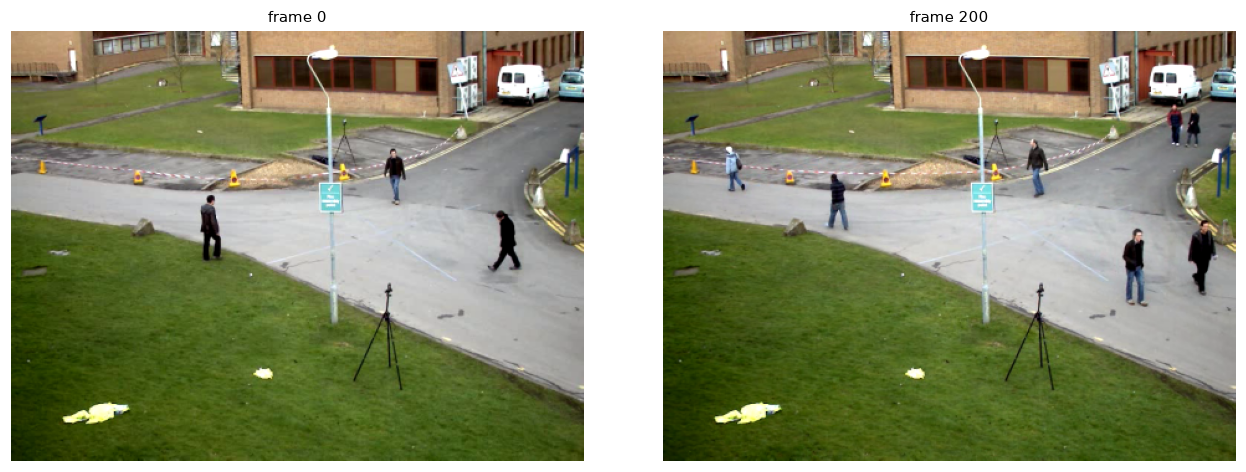

In [5]:
ESCALA = 0.6                       # los cuadros de trabajo se reducen para acelerar el procesamiento
frames, FPS = leer_frames(obtener_video(), max_frames=400, escala=ESCALA)
H, W = frames[0].shape[:2]
print(f'{len(frames)} frames de {W}x{H} a {FPS:.0f} fps')
mostrar([frames[0], frames[200]], ['frame 0', 'frame 200'], cols=2, ancho=6)

## 2. Modelado de fondo: de la diferencia de cuadros a MOG2, KNN y CNT

En esta actividad implementamos dos métodos sencillos de modelado de fondo —**diferencia de cuadros** y **promedio temporal**— y los comparamos con tres algoritmos disponibles en OpenCV:

- **MOG2** – modela cada píxel mediante una mezcla de distribuciones gaussianas y permite adaptar el número de componentes. También ofrece detección de sombras.
- **KNN** – modela el fondo a partir de un historial de muestras y utiliza una estrategia basada en vecinos cercanos para clasificar cada píxel.
- **CNT** – utiliza información de persistencia temporal para determinar qué píxeles pertenecen al fondo. Es un método liviano, pensado para aplicaciones con recursos limitados.

### 👀 ¿Qué observar?

Al comparar las máscaras obtenidas, prestá atención especialmente a:

1. **Diferencia de cuadros:** observar qué partes de un objeto en movimiento son detectadas y cuáles no.
2. **Modelado del fondo:** comparar cómo los distintos métodos separan objetos en movimiento de un fondo que puede presentar pequeñas variaciones.
3. **Sombras:** MOG2 y KNN permiten detectar sombras. Observar cómo aparecen en la máscara y diferenciarlas del primer plano.
4. **Ruido y estabilidad:** observar la presencia de píxeles aislados o regiones incorrectamente clasificadas.
5. **Costo computacional:** comparar el tiempo de procesamiento de cada método y relacionarlo con la complejidad del algoritmo.

In [6]:
class DiferenciaCuadros:
    # Diferencia entre cuadros consecutivos:
    # B_t(p) = |I_t(p) - I_{t-1}(p)| > eps
    def __init__(self, eps=20):
        self.eps, self.prev = eps, None

    def apply(self, f):
        # Convertir a escala de grises y suavizar para reducir
        # pequeñas variaciones y ruido antes de calcular la diferencia.
        g = cv2.GaussianBlur(gris(f), (5, 5), 0)

        # El primer cuadro no tiene un cuadro anterior con el cual comparar.
        if self.prev is None:
            self.prev = g
            return np.zeros_like(g)

        # Calcular la diferencia absoluta entre cuadros consecutivos.
        d = cv2.absdiff(g, self.prev)
        self.prev = g

        # Umbralizar la diferencia para obtener la máscara de movimiento.
        return ((d > self.eps) * 255).astype(np.uint8)


In [7]:
class PromedioMovil:
    # Actualización recursiva del modelo de fondo:
    # B_t = (1 - a) B_{t-1} + a I_t
    #
    # La máscara se obtiene comparando el frame actual con el modelo de fondo:
    # D_t = |I_t - B_t| > eps
    def __init__(self, alfa=0.02, eps=25):
        self.a, self.eps, self.bg = alfa, eps, None

    def apply(self, f):
        # Convertir a escala de grises, suavizar y utilizar float32
        # para realizar correctamente las operaciones del promedio.
        g = cv2.GaussianBlur(gris(f), (5, 5), 0).astype(np.float32)

        # Inicializar el modelo de fondo con el primer frame.
        if self.bg is None:
            self.bg = g.copy()

        # Calcular la diferencia respecto al fondo actual.
        d = np.abs(g - self.bg)

        # Actualizar gradualmente el modelo de fondo.
        self.bg = (1 - self.a) * self.bg + self.a * g

        # Umbralizar la diferencia para obtener la máscara de primer plano.
        return ((d > self.eps) * 255).astype(np.uint8)

In [8]:
def crear_sustractor(nombre):
    # Crear el sustractor correspondiente a cada método.
    if nombre == 'MOG2':
        return cv2.createBackgroundSubtractorMOG2(
            history=300,
            varThreshold=25,
            detectShadows=True
        )
    if nombre == 'KNN':
        return cv2.createBackgroundSubtractorKNN(
            history=300,
            dist2Threshold=400,
            detectShadows=True
        )
    if nombre == 'CNT':
        return cv2.bgsegm.createBackgroundSubtractorCNT()
    if nombre == 'Dif. cuadros':
        return DiferenciaCuadros()
    if nombre == 'Promedio móvil':
        return PromedioMovil()

    raise ValueError(nombre)

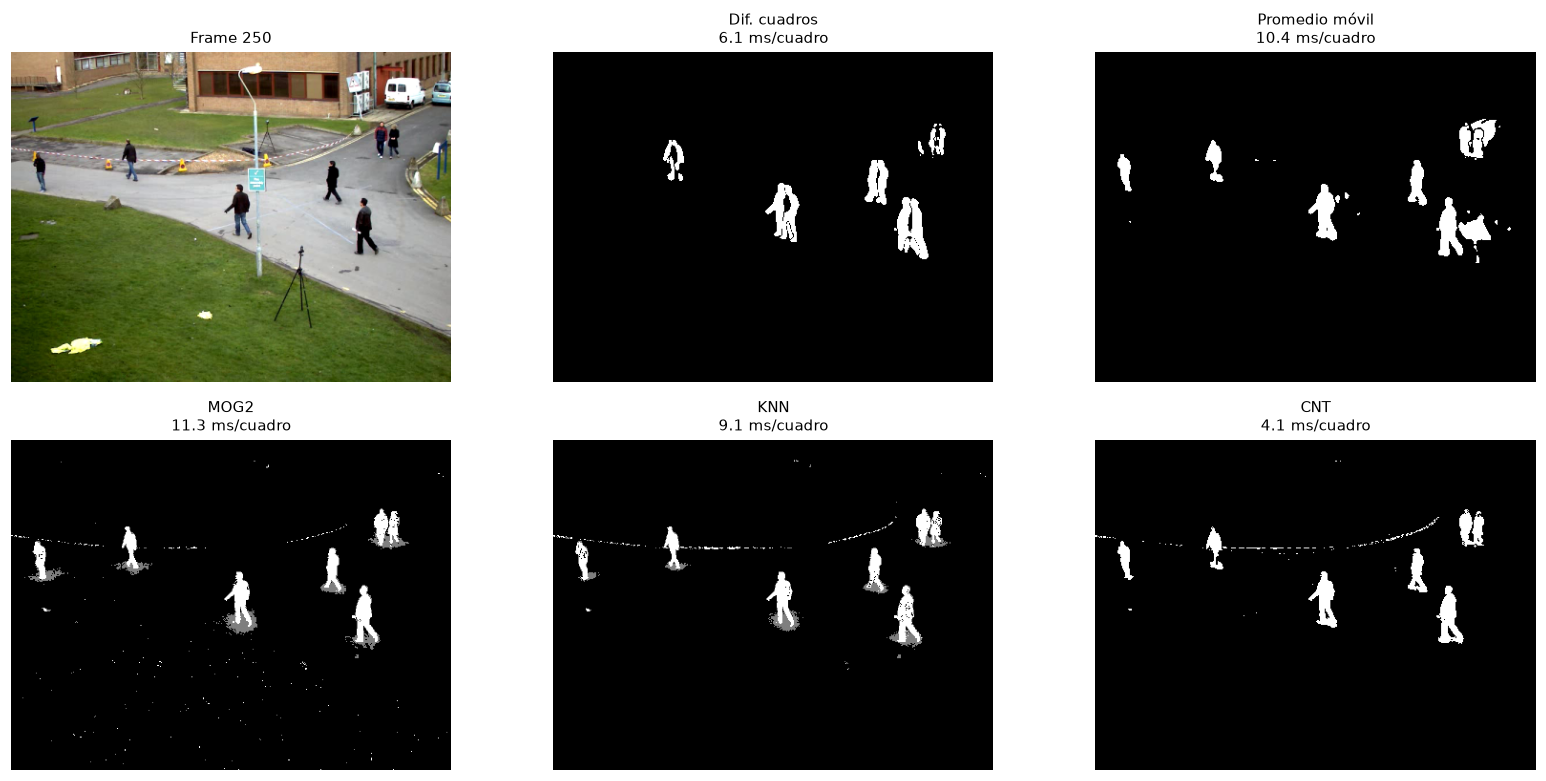

In [9]:

# Métodos que se van a comparar.
METODOS = [
    'Dif. cuadros',
    'Promedio móvil',
    'MOG2',
    'KNN',
    'CNT'
]

# Cuadro utilizado para visualizar y comparar las máscaras finales.
IDX = 250
masks, tiempos, pct = {}, {}, {}

for nom in METODOS:
    s = crear_sustractor(nom)
    t = 0

    # Procesar los primeros IDX + 1 cuadros para permitir que
    # cada método inicialice y actualice su modelo de fondo.
    for i, f in enumerate(frames[:IDX + 1]):
        t0 = time.perf_counter()
        m = s.apply(f)
        t += time.perf_counter() - t0

    # Guardar la última máscara obtenida.
    masks[nom] = m
    # Tiempo promedio de procesamiento por cuadro, en milisegundos.
    tiempos[nom] = 1000 * t / (IDX + 1)
    # Porcentaje de píxeles clasificados como primer plano.
    pct[nom] = 100 * (m == 255).mean()

# Mostrar el frame de referencia y la máscara obtenida por cada método.
mostrar(
    [frames[IDX]] + [masks[n] for n in METODOS],
    ['Frame ' + str(IDX)] +
    [f'{n}\n{tiempos[n]:.1f} ms/cuadro' for n in METODOS],
    cols=3,
    ancho=5
)

### Post-proceso de la máscara (fase 4 del algoritmo)

La máscara generada por el sustractor todavía puede contener **sombras, ruido y pequeños fragmentos**. En esta etapa realizamos tres operaciones antes de obtener las detecciones finales:

1. **Umbralización:** conservamos solamente los píxeles de primer plano (`255`) y descartamos las sombras (`127`).
2. **Procesamiento morfológico:** utilizamos apertura para eliminar pequeños elementos aislados y cierre para unir fragmentos cercanos de un mismo objeto.
3. **Detección de blobs:** mediante `findContours` identificamos las regiones conectadas y descartamos aquellas cuya área sea demasiado pequeña.

Estas funciones se reutilizan en el resto del notebook para convertir las máscaras de los distintos métodos.

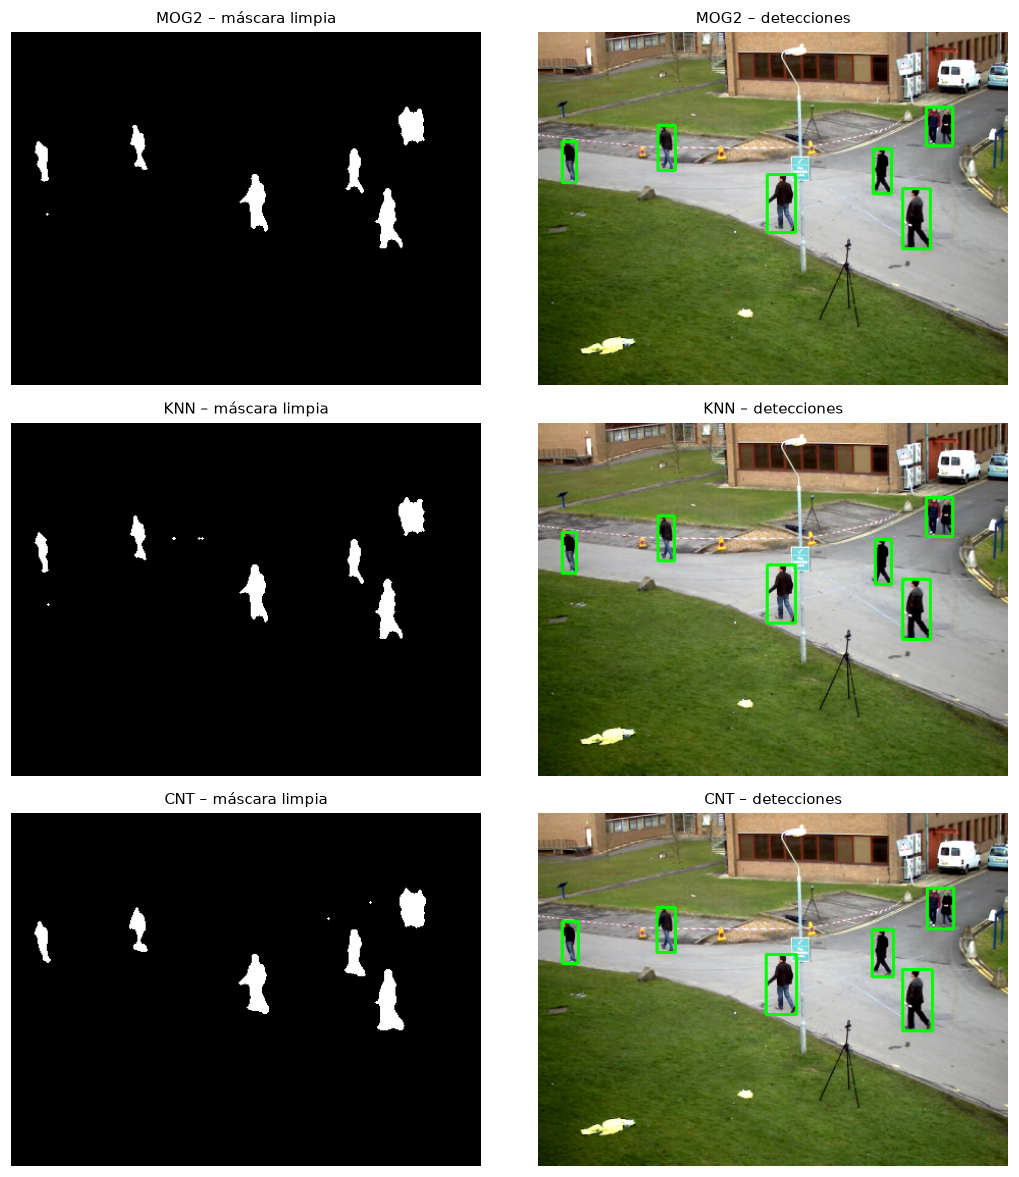

In [10]:
# Definición de los elementos estructurantes que usaremos (elipses de kxk)
K_OPEN = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (3, 3))
K_CLOSE = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (9, 9))

def limpiar_mascara(m):
    # Con MOG2/KNN y detectShadows=True:
    #   0   = fondo, 127 = sombra, 255 = primer plano
    # El umbral > 200 conserva solamente el primer plano.
    _, b = cv2.threshold(m, 200, 255, cv2.THRESH_BINARY)

    # Apertura: elimina pequeños elementos aislados y ruido puntual.
    b = cv2.morphologyEx(b, cv2.MORPH_OPEN, K_OPEN)
    # Cierre: rellena pequeños huecos y une fragmentos cercanos.
    b = cv2.morphologyEx(b, cv2.MORPH_CLOSE, K_CLOSE)
    return b

def detectar_blobs(mask, area_min=120):
    # Buscar únicamente contornos externos de las regiones detectadas.
    cnts, _ = cv2.findContours(
        mask,
        cv2.RETR_EXTERNAL,
        cv2.CHAIN_APPROX_SIMPLE
    )
    # Conservar solamente las regiones cuya área supere el mínimo establecido.
    return [
        cv2.boundingRect(c)
        for c in cnts
        if cv2.contourArea(c) >= area_min
    ]

def dibujar_cajas(f, cajas, color=(0, 255, 0)):
    # Dibujar las cajas delimitadoras sobre una copia del frame original.
    g = f.copy()
    for x, y, w, h in cajas:
        cv2.rectangle(g, (x, y), (x + w, y + h), color, 2)
    return g

salida = []
for nom in ['MOG2', 'KNN', 'CNT']:
    # Limpiar la máscara y extraer las regiones detectadas.
    limpia = limpiar_mascara(masks[nom])
    cajas = detectar_blobs(limpia)
    # Mostrar tanto la máscara procesada como las detecciones.
    salida += [limpia, dibujar_cajas(frames[IDX], cajas) ]

mostrar(salida,
    [
        f'{n} – {t}'
        for n in ['MOG2', 'KNN', 'CNT']
        for t in ['máscara limpia', 'detecciones']
    ],
    cols=2, ancho=5
)

### 💡 Consignas y Reflexiones - Ejercicio 2:

1. **Comparación entre métodos de modelado de fondo**

    * Comparar las máscaras obtenidas mediante **diferencia de cuadros, promedio móvil, MOG2, KNN y CNT**.
    * ¿Por qué la diferencia de cuadros puede detectar principalmente los bordes de un objeto en movimiento?
    * ¿Qué ocurre cuando un objeto permanece quieto durante varios cuadros?

2. **Parámetros de MOG2**

    * Variar `varThreshold` de MOG2 (`10`, `25`, `60`) y `history` (`50`, `300`, `1000`).
    * ¿Cómo cambian los **falsos positivos** y los objetos **fragmentados**?
    * ¿Qué combinación proporciona un mejor equilibrio para esta secuencia?

3. **Post-procesamiento y detección de blobs**

    * Comparar las máscaras antes y después de aplicar **umbralización, apertura y cierre morfológico**.
    * Experimentar modificando `K_OPEN`, `K_CLOSE` y `area_min`. ¿Cómo afectan estos parámetros a la cantidad, forma y continuidad de los objetos detectados?
    * ¿Qué problemas pueden aparecer si los valores son demasiado pequeños o demasiado grandes?

4. **Comparación de rendimiento**

    * Comparar **MOG2, KNN y CNT** considerando la calidad de las máscaras, la estabilidad de las detecciones y el tiempo de procesamiento.
    * Para una aplicación de tracking en tiempo real con recursos limitados, ¿qué método elegirías y qué compromiso estarías haciendo entre velocidad y calidad?

5. **Métodos adicionales — opcional**

    * Probar `cv2.bgsegm.createBackgroundSubtractorGSOC()` y `cv2.bgsegm.createBackgroundSubtractorGMG()`.
    * Comparar sus resultados y tiempos de procesamiento con los métodos anteriores.
    * Tener en cuenta que **GMG necesita aproximadamente 120 cuadros para inicializar el modelo de fondo**.

**Enlaces y Lecturas Sugeridas**

- [OpenCV - Background Subtraction](https://docs.opencv.org/4.x/d1/dc5/tutorial_background_subtraction.html)
- [OpenCV - BackgroundSubtractorMOG2](https://docs.opencv.org/4.x/javadoc/org/opencv/video/BackgroundSubtractorMOG2.html)
- [OpenCV - BackgroundSubtractorKNN](https://docs.opencv.org/4.x/javadoc/org/opencv/video/BackgroundSubtractorKNN.html)
- [OpenCV - Morphological Transformations](https://docs.opencv.org/4.x/d9/d61/tutorial_py_morphological_ops.html)
- [OpenCV - Contour Features](https://docs.opencv.org/4.x/dd/d49/tutorial_py_contour_features.html)